## Neural Network Feature Ablation

This experiment determines the impact of certain design choices of our neural network for options pricing predictions under the Black-Scholes model. Specifically, it tests for the effectiveness of:
- Feature engineering, from absolute prices $(S, K)$ to log-moneyness $\log{\frac{S}{K}},$ along with standardization of both input space $X$ and target space $y.$
- Log-transform of our target (hence predicting $\log{\frac{C}{K}}$ instead of $\frac{C}{K}.$
- Model architecture (4 --> 128 --> 128 --> 64 --> 1) against a reduced variant (4 --> 128 --> 128 --> 1)
- Hybrid loss, comparing a weighted sum of MSE and y * MSE against standard MSE.

We begin with a baseline model incorporating all features above, before performing controlled ablations by removing a single feature at any moment in time while keeping all others constant.


The baseline model is trained on the following dataset. For reproducibility, we retrain the model inside the notebook.
- 100,000 training samples, 10,000 eval samples.
- $\log{\frac{S}{K}} \in [-2, 2]$
- $T \in [0.1, 2],$ with a log-normal distribution.
- $\sigma \in (0.1, 0.5)$
- $r$ set constant at $r = 0.02.$

For implementation details, reference `constants.py`.
 

In [1]:
import sys

sys.path.append("..")

from src.constants import NN_MODEL_PATH
from src.data.dataset_generator import DataConfig, generate_bundle

cfg = DataConfig()
dataset_bundle = generate_bundle(cfg)

In [2]:
from src.training.train_nn import train, set_seed, get_device, predict

# training is done on default hyperparams.
set_seed(42)
device = get_device(use_cpu=True)

X_train, y_train = dataset_bundle.train.X, dataset_bundle.train.y_call
X_val, y_val = dataset_bundle.val.X, dataset_bundle.val.y_call
    
nn_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
)

Epoch 0, Training Loss: 0.87839770, Eval Loss: 0.77281576
Epoch 10, Training Loss: 0.26086006, Eval Loss: 0.23006313
Epoch 20, Training Loss: 0.10896422, Eval Loss: 0.10069548
Epoch 30, Training Loss: 0.04947736, Eval Loss: 0.04822300
Epoch 40, Training Loss: 0.04248786, Eval Loss: 0.04154200
Epoch 50, Training Loss: 0.03112861, Eval Loss: 0.03042949
Epoch 60, Training Loss: 0.02625081, Eval Loss: 0.02545092
Epoch 70, Training Loss: 0.02148022, Eval Loss: 0.02081683
Epoch 80, Training Loss: 0.01749942, Eval Loss: 0.01686755
Epoch 90, Training Loss: 0.01404528, Eval Loss: 0.01348661
Epoch 100, Training Loss: 0.01117307, Eval Loss: 0.01065316
Epoch 110, Training Loss: 0.00891439, Eval Loss: 0.00847348
Epoch 120, Training Loss: 0.00730735, Eval Loss: 0.00693787
Epoch 130, Training Loss: 0.00619703, Eval Loss: 0.00589136
Epoch 140, Training Loss: 0.00535545, Eval Loss: 0.00507409
Epoch 150, Training Loss: 0.00469479, Eval Loss: 0.00444504
Epoch 160, Training Loss: 0.00416378, Eval Loss: 0.

Now we evaluate this control on a few metrics:
- MAE
- RMSE
- Heatmap of rel. error across $T$ and log-moneyness.

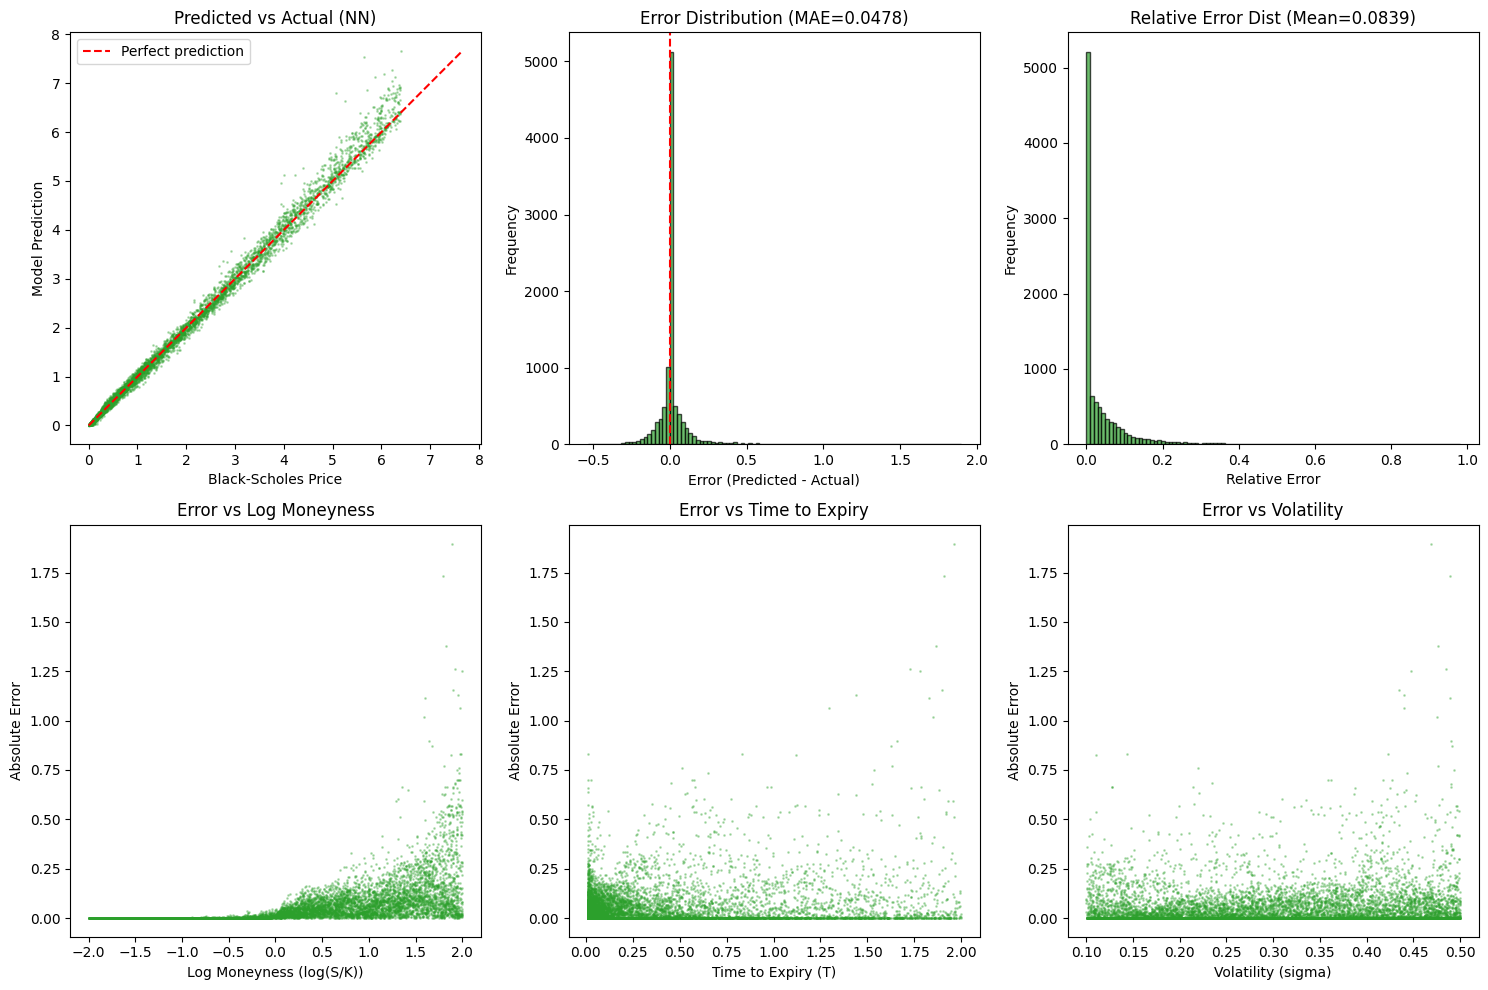

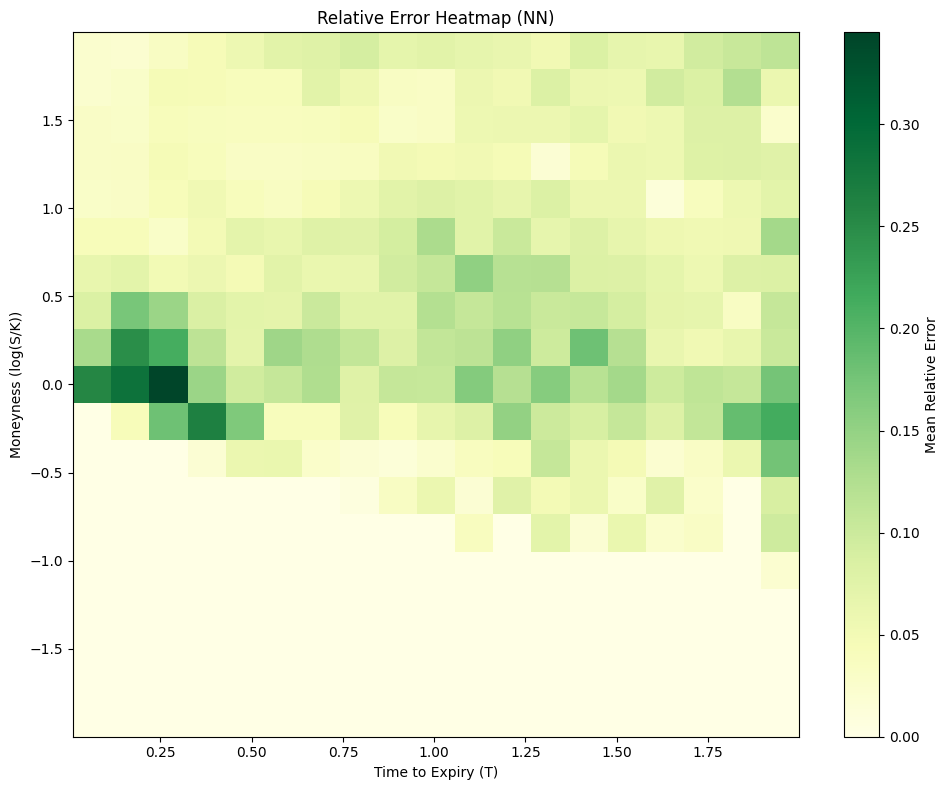

{'mae': np.float32(0.047766905), 'rmse': np.float32(0.10748923), 'mean_relative_error': np.float32(0.08387498), 'median_relative_error': np.float32(0.04823134), 'max_error': np.float32(1.8968425), 'errors': array([ 1.4433980e-02, -5.5324316e-02, -6.5646172e-02, ...,
        7.5293025e-07,  3.5188368e-09, -1.2135457e-09],
      shape=(10000,), dtype=float32), 'abs_errors': array([1.4433980e-02, 5.5324316e-02, 6.5646172e-02, ..., 7.5293025e-07,
       3.5188368e-09, 1.2135457e-09], shape=(10000,), dtype=float32), 'relative_errors': array([0.01567573, 0.0190953 , 0.02475304, ..., 0.        , 0.        ,
       0.        ], shape=(10000,), dtype=float32)}


In [7]:
from src.eval.validate import compute_metrics, plot_validation_results, preprocess_test_data
from src.training.train_nn import predict
import pandas as pd

EVAL_STYLE = {'color': 'tab:green', 'cmap': 'YlGn', 'suffix': '', 'display_name': 'NN'}

X_test_raw, y_test = dataset_bundle.test.X, dataset_bundle.test.y_call
X_test, _ = preprocess_test_data(X_test_raw)
y_pred = predict(nn_model, X_test, norm_params, device="cpu")

metrics = compute_metrics(y_test, 
                          y_pred, 
                          min_value_threshold=0.01)

plot_validation_results(X_test_raw, 
                        y_test, 
                        y_pred, 
                        metrics, 
                        EVAL_STYLE, 
                        save_dir=None)

print(metrics)